# 📊 Caso d'Uso 1: Lo Spam Filter

In [9]:
%%capture
%pip install -q torch scikit-learn numpy pandas matplotlib

In [10]:
import copy
import time
from collections import Counter
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# Device: GPU Apple (MPS) se disponibile, altrimenti CUDA, altrimenti CPU
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print(f"Device in uso: {device}\n")

def sincronizza():
    """Attende la fine delle operazioni sulla GPU, così i tempi misurati sono reali."""
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

Device in uso: mps



## 1. PREPARAZIONE DEI DATI (Dataset italiano: datasets/italian.csv)

In [11]:
# Label: 1 = Spam, 0 = Ham (Messaggio normale)
df = pd.read_csv("datasets/italian.csv")
dati_testo = df["text"].tolist()
labels = df["labels"].tolist()

# --- SPLIT TRAIN / VALIDATION / TEST (70 / 15 / 15, stratificato) ---
# Lo split va fatto PRIMA di costruire TF-IDF e vocabolario, per evitare data leakage
X_train_txt, X_tmp_txt, y_train, y_tmp = train_test_split(
    dati_testo, labels, test_size=0.30, stratify=labels, random_state=SEED)
X_val_txt, X_test_txt, y_val, y_test = train_test_split(
    X_tmp_txt, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(f"Train: {len(X_train_txt)} | Validation: {len(X_val_txt)} | Test: {len(X_test_txt)}\n")

# --- BASELINE CLASSICA: TF-IDF + Naive Bayes (Scikit-Learn) ---
print("--- [BASELINE] TF-IDF + Naive Bayes ---")

# Numero di feature del TF-IDF: le parole che compaiono più di una volta nel training set.
# Le parole viste una sola volta (hapax) sono quasi sempre refusi, nomi propri o numeri:
# non aiutano a generalizzare e aumentano solo la dimensione dei vettori
def conta_parole_ripetute(testi, analizzatore):
    """Numero di parole con più di un'occorrenza nei testi, tokenizzate come fa il TF-IDF."""
    conteggi = Counter(parola for testo in testi for parola in analizzatore(testo))
    return sum(1 for n in conteggi.values() if n > 1)

MAX_FEATURES = conta_parole_ripetute(X_train_txt, TfidfVectorizer().build_analyzer())
print(f"max_features = {MAX_FEATURES} (parole con più di un'occorrenza nel training set)")
vectorizer = TfidfVectorizer(max_features=MAX_FEATURES)
inizio = time.perf_counter()
X_train_tfidf = vectorizer.fit_transform(X_train_txt)  # fit SOLO sul train
tempo_tfidf = time.perf_counter() - inizio
X_val_tfidf = vectorizer.transform(X_val_txt)
X_test_tfidf = vectorizer.transform(X_test_txt)

classificatore_nb = MultinomialNB()
inizio = time.perf_counter()
classificatore_nb.fit(X_train_tfidf, y_train)
tempo_nb_fit = time.perf_counter() - inizio
tempo_nb = tempo_tfidf + tempo_nb_fit  # tempo totale della baseline: TF-IDF + Naive Bayes
pred_val_nb = classificatore_nb.predict(X_val_tfidf)
pred_test_nb = classificatore_nb.predict(X_test_tfidf)
print(f"Val  Accuracy: {accuracy_score(y_val, pred_val_nb) * 100:.2f}%")
print(f"Test Accuracy: {accuracy_score(y_test, pred_test_nb) * 100:.2f}% | "
      f"Test F1: {f1_score(y_test, pred_test_nb):.4f} | Tempo training: {tempo_nb:.3f}s "
      f"(TF-IDF: {tempo_tfidf:.3f}s + NB: {tempo_nb_fit:.3f}s)\n")


# --- PREPARAZIONE PER IL DEEP LEARNING (Tokenizzazione e Padding) ---
# Costruiamo il vocabolario SOLO sui testi di train
parole = sorted(set(" ".join(X_train_txt).lower().split()))
vocabolario = {parola: i+2 for i, parola in enumerate(parole)}  # 0 = padding, 1 = parola sconosciuta
vocabolario["<PAD>"] = 0
vocabolario["<UNK>"] = 1
vocab_size = len(vocabolario)

# Lunghezza delle sequenze (numero di slot): il 95° percentile delle lunghezze dei messaggi
# di training, così almeno il 95% dei messaggi entra senza essere troncato
lunghezze_train = [len(testo.split()) for testo in X_train_txt]
MAX_LEN = int(np.ceil(np.percentile(lunghezze_train, 95)))
print(f"max_len = {MAX_LEN} (copre il {np.mean(np.array(lunghezze_train) <= MAX_LEN) * 100:.1f}% dei messaggi di training)")

def text_to_indices(testo, vocabolario, max_len=20):
    indici = [vocabolario.get(p, vocabolario["<UNK>"]) for p in testo.lower().split()]
    # Padding o troncamento per allineare le lunghezze dei messaggi
    if len(indici) < max_len:
        indici += [0] * (max_len - len(indici))
    else:
        indici = indici[:max_len]
    return indici

def to_tensors(testi, y):
    X = torch.tensor([text_to_indices(t, vocabolario, MAX_LEN) for t in testi])
    return X, torch.tensor(y, dtype=torch.float32)

X_train, y_train_t = to_tensors(X_train_txt, y_train)
X_val, y_val_t = to_tensors(X_val_txt, y_val)
X_test, y_test_t = to_tensors(X_test_txt, y_test)

# Creazione del Dataset PyTorch standard
class SpamDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 64
train_loader = DataLoader(SpamDataset(X_train, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(SpamDataset(X_val, y_val_t), batch_size=256)
test_loader = DataLoader(SpamDataset(X_test, y_test_t), batch_size=256)

Train: 13103 | Validation: 2808 | Test: 2808

--- [BASELINE] TF-IDF + Naive Bayes ---
max_features = 5567 (parole con più di un'occorrenza nel training set)
Val  Accuracy: 96.44%
Test Accuracy: 96.33% | Test F1: 0.9647 | Tempo training: 0.063s (TF-IDF: 0.062s + NB: 0.002s)

max_len = 20 (copre il 96.8% dei messaggi di training)


## 2. DEFINIZIONE DELLE ARCHITETTURE NEURALI (PyTorch)

In [12]:
# Modello Ricorrente Unificato (Gestisce sia RNN classica, che GRU, che LSTM)
class SpamRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, rnn_type="LSTM"):
        super().__init__()
        # padding_idx=0 dice alla rete di ignorare i vettori di riempimento
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        if rnn_type == "RNN":
            self.core = nn.RNN(embedding_dim, hidden_dim, batch_first=True)
        elif rnn_type == "GRU":
            self.core = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        elif rnn_type == "LSTM":
            self.core = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)

        self.fc = nn.Linear(hidden_dim, 1) # Spara 1 singolo Logit grezzo [0.5]

    def forward(self, text):
        embedded = self.embedding(text)
        if isinstance(self.core, nn.LSTM):
            output, (hidden, cell) = self.core(embedded)
        else:
            output, hidden = self.core(embedded)
        # Esaminiamo l'ultimo hidden state emesso
        return self.fc(hidden[-1, :, :]).squeeze(1)

# Modello Parallelo basato su Transformer (Self-Attention)
class SpamTransformer(nn.Module):
    def __init__(self, vocab_size, embedding_dim, nhead, hidden_dim, num_layers, max_len=20):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.pos_embedding = nn.Embedding(max_len, embedding_dim)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim, nhead=nhead, dim_feedforward=hidden_dim, batch_first=True, activation='relu'
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc = nn.Linear(embedding_dim, 1)

    def forward(self, text):
        batch_size, seq_len = text.size()
        pos = torch.arange(0, seq_len).unsqueeze(0).repeat(batch_size, 1).to(text.device)

        # Somma Semantica + Posizionale [0.5]
        x = self.embedding(text) + self.pos_embedding(pos)
        features = self.transformer(x)
        # Pooling: facciamo la media delle caratteristiche di tutte le parole del messaggio
        pooled = features.mean(dim=1)
        return self.fc(pooled).squeeze(1)

## 3. PIPELINE DI ADDESTRAMENTO E CONFRONTO

In [13]:
costanti_comuni = {"vocab_size": vocab_size, "embedding_dim": 8, "hidden_dim": 8}

# Creiamo una lista contenente le nostre configurazioni di Deep Learning
modelli_da_testare = {
    "RNN Classica": SpamRNN(**costanti_comuni, rnn_type="RNN"),
    "Rete GRU": SpamRNN(**costanti_comuni, rnn_type="GRU"),
    "Rete LSTM": SpamRNN(**costanti_comuni, rnn_type="LSTM"),
    "Transformer": SpamTransformer(vocab_size=vocab_size, embedding_dim=8, nhead=2, hidden_dim=8, num_layers=1, max_len=MAX_LEN)
}

# Funzione di Loss ottimizzata per la classificazione binaria dai Logit [0.5]
criterion = nn.BCEWithLogitsLoss()


## Dettagli sulla valutazione dei modelli:

*Precision*: tra i messaggi che il modello ha segnato come spam, quanti lo sono davvero. È bassa quando ci sono molti falsi positivi, cioè messaggi legittimi finiti nello spam.

*Recall*: tra tutti i messaggi che sono davvero spam, quanti il modello ne ha trovati. È bassa quando ci sono molti falsi negativi, cioè spam che arriva nella casella.

*F1-score* = 2 · (precision · recall) / (precision + recall)
Va da 0 a 1. La media armonica penalizza gli squilibri: se una delle due metriche è bassa, anche l'F1 è basso, anche quando l'altra è alta. (NB: nel nostro caso, il dataset è bilanciato ma è buona norma riportare anche l'F1)

In [14]:

def valuta(modello, loader):
    """Restituisce loss media, accuratezza (%) e F1-score (media tra precision e recall) del modello sul loader."""
    modello.eval()
    loss_tot, tutte_pred, tutte_y = 0.0, [], []
    with torch.no_grad():
        for batch_X, batch_y in loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            logits = modello(batch_X)
            loss_tot += criterion(logits, batch_y).item() * len(batch_y)
            # Convertiamo i logit in predizioni binarie (se logit > 0 la probabilità è > 50%) [0.5]
            tutte_pred.append((logits > 0).float().cpu())
            tutte_y.append(batch_y.cpu())
    pred = torch.cat(tutte_pred).numpy()
    y = torch.cat(tutte_y).numpy()
    return loss_tot / len(y), accuracy_score(y, pred) * 100, f1_score(y, pred)

def misura_inferenza(predici, testi, ripetizioni=5, n_singoli=300):
    """Tempo di inferenza dal testo grezzo alla predizione (preprocessing incluso).
    Restituisce (µs per messaggio in batch, latenza mediana in ms per singolo messaggio)."""
    predici(testi[:10])  # warm-up (la prima chiamata su GPU include l'inizializzazione dei kernel)
    tempi_batch = []
    for _ in range(ripetizioni):
        inizio = time.perf_counter()
        predici(testi)
        tempi_batch.append(time.perf_counter() - inizio)
    tempi_singoli = []
    for testo in testi[:n_singoli]:
        inizio = time.perf_counter()
        predici([testo])
        tempi_singoli.append(time.perf_counter() - inizio)
    return np.median(tempi_batch) / len(testi) * 1e6, np.median(tempi_singoli) * 1e3

def predici_rete(modello, testi):
    X = torch.tensor([text_to_indices(t, vocabolario, MAX_LEN) for t in testi]).to(device)
    with torch.no_grad():
        # .cpu() attende la fine del calcolo sulla GPU: il tempo misurato è reale
        return (modello(X) > 0).cpu()

def predici_baseline(testi):
    return classificatore_nb.predict(vectorizer.transform(testi))

NUM_EPOCHE = 15

inf_batch_nb, inf_singolo_nb = misura_inferenza(predici_baseline, X_test_txt)
print(f"Baseline TF-IDF + NB | Inferenza: {inf_batch_nb:.1f} µs/msg (batch) | {inf_singolo_nb:.3f} ms (singolo msg)\n")

print("--- AVVIO TRAINING DEI MODELLI DEEP LEARNING ---")
risultati = {
    "TF-IDF + Naive Bayes": {
        "best_epoch": None,
        "val_acc": accuracy_score(y_val, pred_val_nb) * 100,
        "test_acc": accuracy_score(y_test, pred_test_nb) * 100,
        "test_f1": f1_score(y_test, pred_test_nb),
        "tempo_totale_s": tempo_nb,
        "tempo_per_epoca_s": None,
        "tempo_a_best_s": tempo_nb,
        "inferenza_batch_us_msg": inf_batch_nb,
        "inferenza_singolo_ms": inf_singolo_nb,
    }
}
for nome, modello in modelli_da_testare.items():
    modello = modello.to(device)
    # Assegniamo l'ottimizzatore Adam ad ogni specifico modello [0.5]
    optimizer = optim.Adam(modello.parameters(), lr=0.01)

    miglior_val_loss, miglior_stato, miglior_epoca = float("inf"), None, 0
    tempi_epoca = []  # solo tempo di training (la validazione è esclusa)
    for epoca in range(1, NUM_EPOCHE + 1):
        sincronizza()
        inizio = time.perf_counter()
        modello.train()
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            optimizer.zero_grad()
            logits = modello(batch_X)
            loss = criterion(logits, batch_y)
            loss.backward() # Backpropagation [0.5]
            optimizer.step() # Aggiornamento pesi via Adam [0.5]
        sincronizza()
        tempi_epoca.append(time.perf_counter() - inizio)

        # Valutazione sul validation set a fine epoca: teniamo i pesi migliori
        val_loss, val_acc, _ = valuta(modello, val_loader)
        if val_loss < miglior_val_loss:
            miglior_val_loss, miglior_epoca = val_loss, epoca
            miglior_stato = copy.deepcopy(modello.state_dict())

    # Valutazione finale sul test set (una sola volta) con i pesi della miglior epoca
    modello.load_state_dict(miglior_stato)
    _, val_acc, _ = valuta(modello, val_loader)
    _, test_acc, test_f1 = valuta(modello, test_loader)
    modello.eval()
    inf_batch, inf_singolo = misura_inferenza(lambda testi: predici_rete(modello, testi), X_test_txt)
    risultati[nome] = {
        "best_epoch": miglior_epoca,
        "val_acc": val_acc,
        "test_acc": test_acc,
        "test_f1": test_f1,
        "tempo_totale_s": sum(tempi_epoca),
        "tempo_per_epoca_s": np.mean(tempi_epoca),
        "tempo_a_best_s": sum(tempi_epoca[:miglior_epoca]),  # tempo necessario per arrivare ai pesi migliori
        "inferenza_batch_us_msg": inf_batch,
        "inferenza_singolo_ms": inf_singolo,
    }

    print(f"Modello: {nome.ljust(13)} | Best epoch: {miglior_epoca:2d} | "
          f"Val Acc: {val_acc:.2f}% | Test Acc: {test_acc:.2f}% | Test F1: {test_f1:.4f} | "
          f"Tempo: {sum(tempi_epoca):.1f}s ({np.mean(tempi_epoca):.2f}s/epoca) | "
          f"Inferenza: {inf_batch:.1f} µs/msg (batch) | {inf_singolo:.3f} ms (singolo msg)")

Baseline TF-IDF + NB | Inferenza: 4.3 µs/msg (batch) | 0.171 ms (singolo msg)

--- AVVIO TRAINING DEI MODELLI DEEP LEARNING ---
Modello: RNN Classica  | Best epoch:  4 | Val Acc: 87.89% | Test Acc: 87.75% | Test F1: 0.8846 | Tempo: 16.3s (1.09s/epoca) | Inferenza: 4.3 µs/msg (batch) | 1.560 ms (singolo msg)
Modello: Rete GRU      | Best epoch:  2 | Val Acc: 96.33% | Test Acc: 96.26% | Test F1: 0.9633 | Tempo: 20.6s (1.37s/epoca) | Inferenza: 5.4 µs/msg (batch) | 1.865 ms (singolo msg)
Modello: Rete LSTM     | Best epoch:  2 | Val Acc: 95.48% | Test Acc: 96.26% | Test F1: 0.9631 | Tempo: 8.6s (0.58s/epoca) | Inferenza: 4.1 µs/msg (batch) | 0.626 ms (singolo msg)
Modello: Transformer   | Best epoch:  3 | Val Acc: 96.26% | Test Acc: 95.69% | Test F1: 0.9586 | Tempo: 11.0s (0.73s/epoca) | Inferenza: 5.1 µs/msg (batch) | 0.833 ms (singolo msg)


## 4. CONFRONTO ACCURATEZZA vs TEMPO DI ADDESTRAMENTO

In [15]:
tabella = pd.DataFrame(risultati).T
tabella = tabella.astype({c: float for c in tabella.columns if c != "best_epoch"})
print("\n--- CONFRONTO ACCURATEZZA vs TEMPO (ordinato per Test Accuracy) ---")
print(tabella.sort_values("test_acc", ascending=False).round(3).to_string())


--- CONFRONTO ACCURATEZZA vs TEMPO (ordinato per Test Accuracy) ---
                      best_epoch  val_acc  test_acc  test_f1  tempo_totale_s  tempo_per_epoca_s  tempo_a_best_s  inferenza_batch_us_msg  inferenza_singolo_ms
TF-IDF + Naive Bayes         NaN   96.439    96.332    0.965           0.063                NaN           0.063                   4.254                 0.171
Rete GRU                     2.0   96.332    96.261    0.963          20.576              1.372           2.875                   5.425                 1.865
Rete LSTM                    2.0   95.477    96.261    0.963           8.647              0.576           1.294                   4.136                 0.626
Transformer                  3.0   96.261    95.691    0.959          10.960              0.731           2.094                   5.117                 0.833
RNN Classica                 4.0   87.892    87.749    0.885          16.283              1.086           4.215                   4.314      

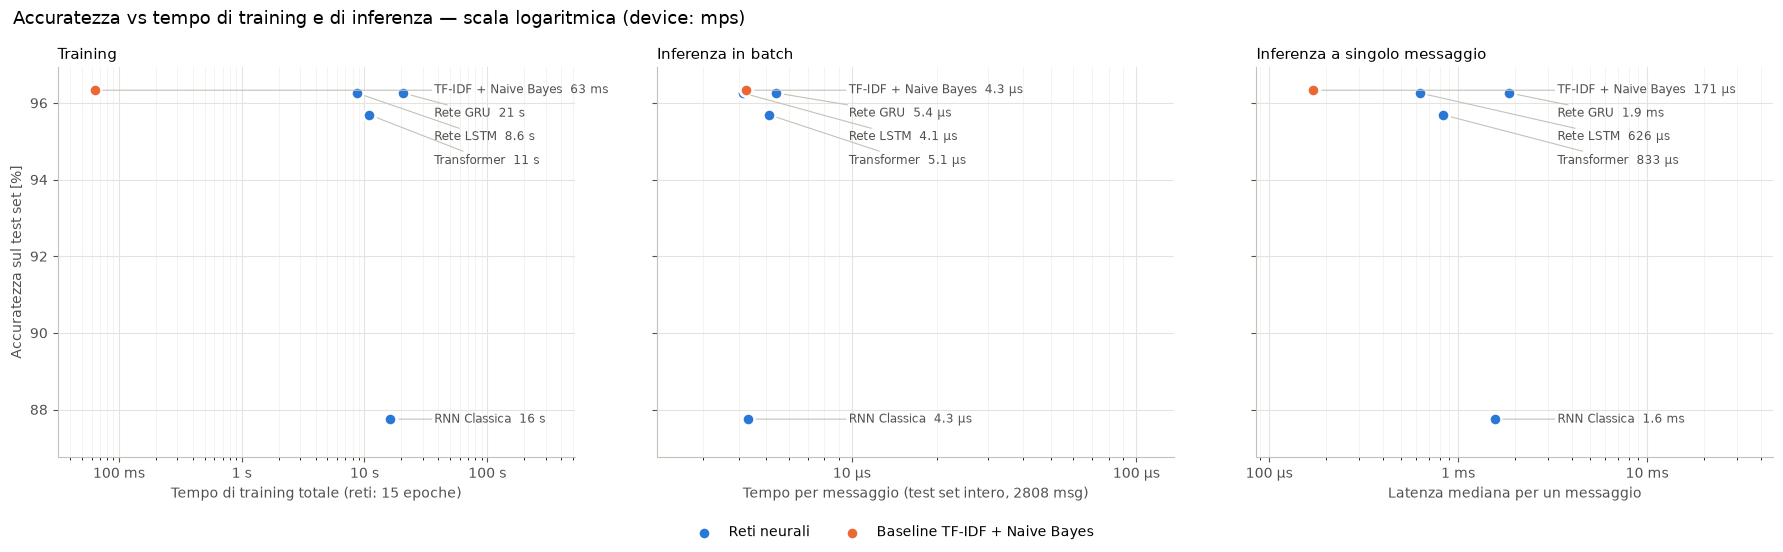

In [16]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Accuratezza vs tempo (training e inferenza): in alto a sinistra = migliore (più accurato e più veloce)
COLORE_NEURALI = "#2a78d6"   # reti neurali
COLORE_BASELINE = "#eb6834"  # baseline classica
COLORE_TESTO = "#52514e"

neurali = tabella[tabella["best_epoch"].notna()]
baseline = tabella[tabella["best_epoch"].isna()]

def formatta_secondi(t):
    """Formatta un tempo in secondi con l'unità più leggibile."""
    valore, unita = (t * 1e6, "µs") if t < 1e-3 else (t * 1e3, "ms") if t < 1 else (t, "s")
    return f"{valore:.1f} {unita}" if valore < 10 else f"{valore:.0f} {unita}"

def formatta_tick(t, _):
    if t < 1e-3:
        return f"{t * 1e6:g} µs"
    return f"{t * 1e3:g} ms" if t < 1 else f"{t:g} s"

def disegna_pannello(ax, colonna, scala, titolo, xlabel):
    """Scatter accuratezza vs tempo (scala log) per una colonna di tempi della tabella.
    `scala` converte i valori della colonna in secondi."""
    tempi = tabella[colonna] * scala
    ax.scatter(tempi[neurali.index], neurali["test_acc"], s=80, zorder=3,
               color=COLORE_NEURALI, edgecolor="white", linewidth=2, label="Reti neurali")
    ax.scatter(tempi[baseline.index], baseline["test_acc"], s=80, zorder=3,
               color=COLORE_BASELINE, edgecolor="white", linewidth=2, label="Baseline TF-IDF + Naive Bayes")

    ax.set_xscale("log")
    t_min, t_max = tempi.min(), tempi.max()
    ax.set_xlim(t_min / 2, t_max * 25)  # spazio a destra per la colonna di etichette
    y_min, y_max = tabella["test_acc"].min() - 1, tabella["test_acc"].max() + 0.6
    ax.set_ylim(y_min, y_max)

    # Etichette in colonna a destra, distanziate per non sovrapporsi, collegate al punto
    x_label = t_max * 1.8
    distanza_minima = (y_max - y_min) * 0.06
    y_prec = float("inf")
    for nome, riga in tabella.sort_values("test_acc", ascending=False).iterrows():
        y_label = min(riga["test_acc"], y_prec - distanza_minima)
        y_prec = y_label
        ax.annotate(f"{nome}  {formatta_secondi(tempi[nome])}",
                    xy=(tempi[nome], riga["test_acc"]), xytext=(x_label, y_label),
                    va="center", fontsize=8.5, color=COLORE_TESTO,
                    arrowprops=dict(arrowstyle="-", color="#c3c2b7", linewidth=0.8, shrinkA=0, shrinkB=6))

    ax.xaxis.set_major_formatter(FuncFormatter(formatta_tick))
    ax.set_title(titolo, loc="left", fontsize=11)
    ax.set_xlabel(xlabel, color=COLORE_TESTO)
    ax.grid(True, which="major", color="#e4e3df", linewidth=0.8)
    ax.grid(True, which="minor", axis="x", color="#f0efec", linewidth=0.5)
    ax.set_axisbelow(True)
    for lato in ("top", "right"):
        ax.spines[lato].set_visible(False)
    for lato in ("left", "bottom"):
        ax.spines[lato].set_color("#c3c2b7")
    ax.tick_params(colors=COLORE_TESTO)

fig, assi = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
disegna_pannello(assi[0], "tempo_totale_s", 1, "Training",
                 f"Tempo di training totale (reti: {NUM_EPOCHE} epoche)")
disegna_pannello(assi[1], "inferenza_batch_us_msg", 1e-6, "Inferenza in batch",
                 f"Tempo per messaggio (test set intero, {len(X_test_txt)} msg)")
disegna_pannello(assi[2], "inferenza_singolo_ms", 1e-3, "Inferenza a singolo messaggio",
                 "Latenza mediana per un messaggio")
assi[0].set_ylabel("Accuratezza sul test set [%]", color=COLORE_TESTO)

fig.suptitle(f"Accuratezza vs tempo di training e di inferenza — scala logaritmica (device: {device})",
             x=0.01, ha="left", fontsize=13)
# Legenda unica, fuori dai grafici
gestori, etichette = assi[0].get_legend_handles_labels()
fig.legend(gestori, etichette, loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()